# Settings

In [55]:
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/006_mouse_long/params.json"

use_nsi = True #!if using nsi, load nsi data in this order 1. zm 2. dc1 3. dc2
bf_matrix_paths = [
    "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/test_classes/beamformed_apodized/001_test_zm.npy",
    "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/test_classes/beamformed_apodized/001_test_dc1.npy",
    "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/test_classes/beamformed_apodized/001_test_dc2.npy"

    #"/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/test_classes/beamformed_apodized/001_test_rectangle.npy"
]
complex_bf = False

#Real data settings
using_matlab_data = False
matlab_bf_data_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data_mat/005_mouse/001_BM.mat"
interpolate_data = True

#Filters
run_hp = False
run_SVD = False
run_hp_SVD = True
directional_filter = False

#Saving params
save_data = True
save_image = True
bf_data_path = "./data_filtered/"
folder_name = "test_classes"
beamformed_filtered_matrix_name = "001_test"

# Imports

In [56]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 
import json
import os
from scipy.signal import butter, lfilter, envelope
from scipy.io import loadmat
from kneed import KneeLocator
from matplotlib.colors import LinearSegmentedColormap

# Import parameters

In [57]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [58]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"] 

    return params

In [59]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = params["rf"]["C"] #speed of sound

print(f"Max acquisition depth : {C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.011827200000000001 m


# Create workspace

In [60]:
if not os.path.exists(f"{bf_data_path}{folder_name}"):
    os.makedirs(f"{bf_data_path}{folder_name}")
    print(f"Folder {bf_data_path}{folder_name} doesn't exist. Setting up the folder.")

os.makedirs(f"{bf_data_path}{folder_name}/filtered_bf", exist_ok=True)
os.makedirs(f"{bf_data_path}{folder_name}/images", exist_ok=True)

# Import BF matrix

In [61]:
if using_matlab_data:
    bf_matrix = loadmat(matlab_bf_data_path)
    bf_matrix = list(bf_matrix.values())[-1]

    if bf_matrix.ndim == 4:
        bf_matrix = np.reshape(bf_matrix, (bf_matrix.shape[0], bf_matrix.shape[1], bf_matrix.shape[2] * bf_matrix.shape[3]))
    print("Imported bf matrix with shape: ", bf_matrix.shape)
else:
    matrices_tmp = []
    for path in bf_matrix_paths:
        if not os.path.exists(path):
            raise FileNotFoundError(f"File {path} does not exist.")
        matrices_tmp.append(np.load(path))
    bf_matrix = np.concatenate(matrices_tmp, axis = 0)
    bf_matrix
    del matrices_tmp

    print("Imported bf matrix with shape: ", bf_matrix.shape)


if interpolate_data:
    samples = params["rf"]["upsampled_samples"]
    sampling_rate = params["rf"]["upsampled_sampling_rate"]
else:
    samples = params["rf"]["samples"]
    sampling_rate = params["rf"]["sampling_rate"]


Imported bf matrix with shape:  (600, 256, 160)


In [62]:
# bf_matrix = np.reshape(bf_matrix, (bf_matrix.shape[0], bf_matrix.shape[1], 20))
# bf_matrix = np.real(bf_matrix)

In [63]:
# pixel_width = params["image"]["dx"]
# pixel_height = params["image"]["dz"]
# physical_aspect = pixel_width / pixel_height

# plt.figure(figsize=(10, 8))
# plt.imshow(np.abs(np.sum(bf_matrix, axis=2)), cmap='viridis', aspect=physical_aspect)

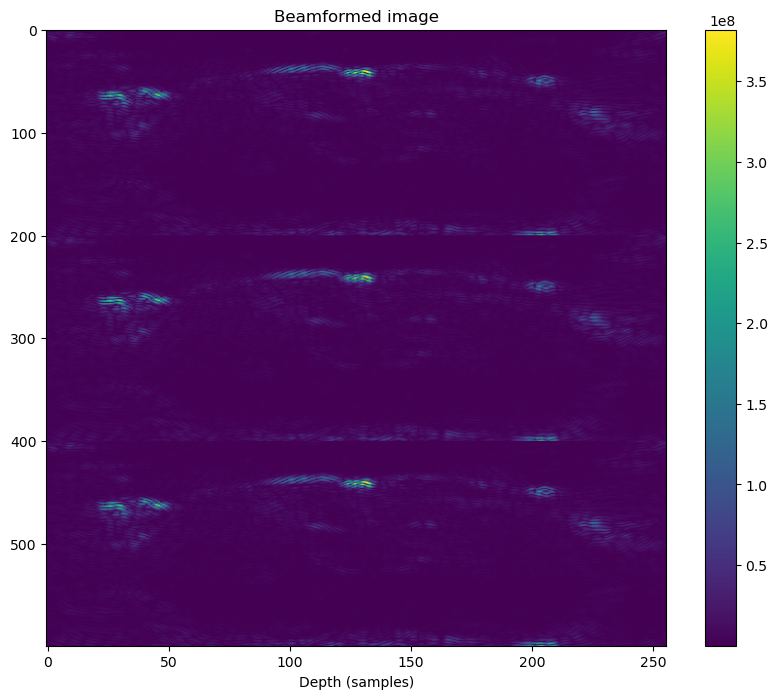

In [64]:
plt.figure(figsize=(10, 8)) 
plt.imshow(np.abs(np.sum(bf_matrix, axis=2)), aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("Beamformed image")
plt.xlabel("Depth (samples)")
plt.show()

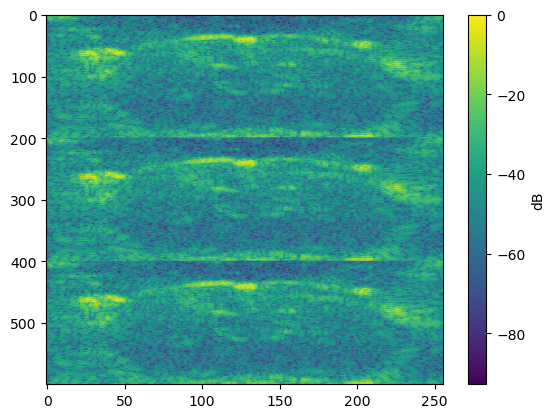

In [65]:
plt.imshow(20 * np.log10(np.sum(np.abs(bf_matrix), axis=2) / np.max(np.sum(np.abs(bf_matrix), axis=2))), aspect='auto', cmap='viridis')
plt.colorbar(label='dB')
plt.show()

# Save data

In [66]:
def save_beamformed_data(bf_matrix, filename, destination):
    np.save(f"{destination}{filename}", bf_matrix)
    print(f"Beamformed data of shape {bf_matrix.shape} saved at: {destination}{filename}.npy")

# Filters

## SVD

In [67]:
def filter_svd(bf, nelim):
    if nelim == 0:
        return bf, None
    #get dimensions of data
    nz, nx, nt = bf.shape
    #reshape to 2D matrix (space-time)
    m = np.reshape(bf, (nz*nx, nt))
    #remove mean from each row
    m = m - np.mean(m, axis=1, keepdims=True)
    #perform SVD decomposition
    U, S, Vt = np.linalg.svd(m, full_matrices=False)
    #create diagonal matrix from singular values
    Sf = np.diag(S)
    #set smallest singular values to zero (eliminating noise)
    Sf[:nelim, :nelim] = 0
    #reconstruct filtered matrix 
    mf = U @ Sf @ Vt
    #reshape back to 3D
    bff = np.reshape(mf, (nz, nx, nt))
    #return filtered data and singular values
    return bff, S

In [68]:
if run_SVD:
    filtered_svd, S = filter_svd(bf_matrix, 10)
    plt.imshow(20 * np.log10(np.sum(np.abs(filtered_svd),axis=2) / np.max(np.sum(np.abs(filtered_svd), axis=2))), aspect='auto', cmap='viridis', vmin=-60, vmax=0)
    plt.colorbar(label='dB')
    plt.title('SVD filtered beamformed data')

    if save_data and not use_nsi:
        save_beamformed_data(np.sum(np.abs(filtered_svd), axis=2), f"{beamformed_filtered_matrix_name}_svd", f"{bf_data_path}{folder_name}/filtered_bf/")

    if save_image and not use_nsi:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_svd.png")
        
    plt.show()

## High Pass

In [69]:
def filter_hp(bf, fsam, f, nrebound):

    #subtract continuous componen
    bf  = bf -  np.mean(bf, axis=2, keepdims=True)
    #butterworth high-pass filter
    b, a = butter(3, f*0.6, 'highpass', output='ba', fs=fsam)
    #apply filter along the time dimension
    bff = lfilter(b, a, bf, axis=2)
    #the first nelim images are eliminated because the filter border effect
    if nrebound > 0:
        bff[:,:,0:nrebound] = 0
        
    return bff

In [70]:
if run_hp:    
    filtered_hp = filter_hp(bf_matrix, sampling_rate, params["rf"]["frequency"], 0)
    # plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp),axis=2) / np.max(np.sum(np.abs(filtered_hp),axis=2))), aspect='auto', cmap='viridis')
    plt.imshow(np.sum(np.abs(filtered_hp),axis=2), aspect='auto', cmap='viridis')

    plt.colorbar(label='dB')
    plt.title('High-pass filtered beamformed data')

    if save_data and not use_nsi:
        save_beamformed_data(np.sum(np.abs(filtered_hp), axis=2), f"{beamformed_filtered_matrix_name}_hp", f"{bf_data_path}{folder_name}/filtered_bf/")

    if save_image and not use_nsi:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_hp.png")
        
    plt.show()

## HP + SVD

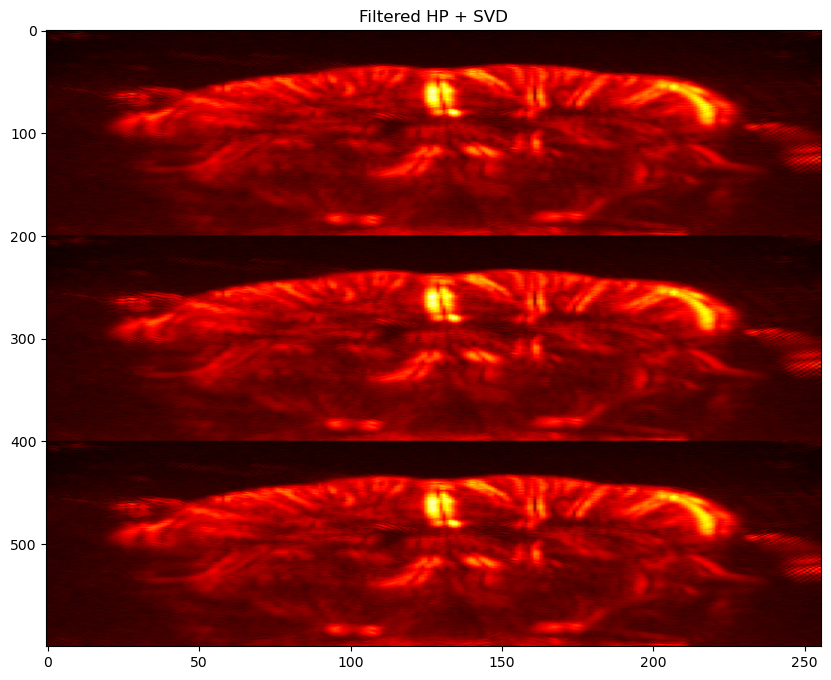

In [71]:
if run_hp_SVD:
    filtered_hp_svd = filter_hp(bf_matrix, sampling_rate, params["rf"]["frequency"], 0)
    filtered_hp_svd, S = filter_svd(filtered_hp_svd, 10)

    plt.figure(figsize=(10, 8))
    plt.imshow(np.sqrt(np.sum(np.abs(filtered_hp_svd),axis=2)), aspect='auto', cmap='hot')
    # plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2))), aspect='auto', cmap='viridis', vmin=-60, vmax=0)
    # plt.colorbar(label='Amplitude')
    plt.title(f"Filtered HP + SVD")

    if save_data and not use_nsi:
        save_beamformed_data(np.sum(np.abs(filtered_hp_svd), axis=2), f"{beamformed_filtered_matrix_name}_hp_svd", f"{bf_data_path}{folder_name}/filtered_bf/")

    if save_image and not use_nsi:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_hp_svd.png")

    plt.show()

Optimal number of singular values to remove: 9


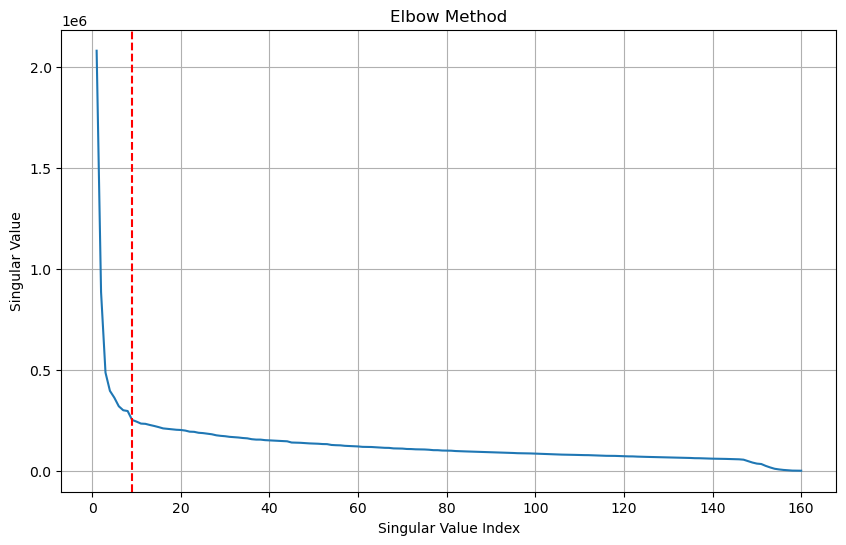

In [72]:
if run_hp_SVD:
    kneedle = KneeLocator(range(1, len(S) + 1), S, curve='convex', direction='decreasing')
    print(f"Optimal number of singular values to remove: {kneedle.elbow}")

    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(S) + 1), S)
    plt.axvline(x=kneedle.elbow, color='r', linestyle='--')
    plt.title('Elbow Method')
    plt.xlabel('Singular Value Index')
    plt.ylabel('Singular Value')
    plt.grid()

In [73]:
def get_envelope(bf_matrix, frames, complex_arg = False):
    lateral_resolution = bf_matrix.shape[1]
    samples = bf_matrix.shape[0]

    env = np.zeros((samples, lateral_resolution, frames))
    
    for i in range(0, frames):
        for j in range(0, lateral_resolution):
            if complex_arg:
                env[:,j,i] = np.abs(bf_matrix[:,j,i])
            else:
                env[:,j,i] = envelope(bf_matrix[:,j,i], residual=None)
    return env

# Phase shift / Movement filter

In [74]:
def calculate_axis_doppler_power(time_signal, sampling_rate):

  n = len(time_signal)

  time_signal_fft = np.fft.fft(time_signal)

  freq_f = np.fft.fftfreq(n, 1/sampling_rate)

  #energy Spectral Density (ESD) |Z_F(ω)|^2
  esd = np.abs(time_signal_fft)**2

  positive_freq_mask = freq_f >= 0
  negative_freq_mask = freq_f < 0

  if use_nsi:
    pos_flow = np.sum(envelope(esd[positive_freq_mask], residual=None)) 
    neg_flow = np.sum(envelope(esd[negative_freq_mask], residual=None))
  else:
    pos_flow = np.sum(esd[positive_freq_mask]) 
    neg_flow = np.sum(esd[negative_freq_mask]) 

  return pos_flow, neg_flow

def get_doppler_flow_images(rf_matrix, sampling_rate):

  num_depth, num_lateral, num_time = rf_matrix.shape

  pos_flow_image = np.zeros((num_depth, num_lateral))
  neg_flow_image = np.zeros((num_depth, num_lateral))

  for i in range(num_depth):  #depth
    for j in range(num_lateral):  #lateral

      time_signal = rf_matrix[i, j, :]

      pos_flow, neg_flow = calculate_axis_doppler_power(time_signal, sampling_rate)

      pos_flow_image[i, j] = pos_flow
      neg_flow_image[i, j] = neg_flow

  return pos_flow_image, neg_flow_image

In [75]:
def filter_movement(rf_data, frames, direction = "up"):
    filtered_rf_data = np.zeros_like(rf_data, dtype=np.complex64)

    instantaneous_phase = np.angle(rf_data)

    for i in range(0, rf_data.shape[1]):    #tranducers
        for j in range(0, rf_data.shape[0]):    #samples depth
            for k in range(1 , frames):  #frames

                phase_shift = instantaneous_phase[j,i,k] - instantaneous_phase[j,i,k-1]
                if direction == "up":
                    filtered_rf_data[j,i,k] = 0 if phase_shift > 0 else rf_data[j,i,k]
                elif direction == "down":
                    filtered_rf_data[j,i,k] = 0 if phase_shift < 0 else rf_data[j,i,k]

    
    return filtered_rf_data

In [76]:
def filter_movement_nsi(rf_data_zm, rf_data_dc1, rf_data_dc2, frames, direction = "up"):

    rf_data = [rf_data_zm, rf_data_dc1, rf_data_dc2]

    filtered_rf_data_zm = np.zeros_like(rf_data_zm, dtype=np.complex64)
    filtered_rf_data_dc1 = np.zeros_like(rf_data_dc1, dtype=np.complex64)
    filtered_rf_data_dc2 = np.zeros_like(rf_data_dc2, dtype=np.complex64)

    filtered_rf_data = [filtered_rf_data_zm, filtered_rf_data_dc1, filtered_rf_data_dc2]

    instantaneous_phase_zm = np.angle(rf_data_zm)
    instantaneous_phase_dc1 = np.angle(rf_data_dc1)
    instantaneous_phase_dc2 = np.angle(rf_data_dc2)

    instantaneous_phase = [instantaneous_phase_zm, instantaneous_phase_dc1, instantaneous_phase_dc2]
    #instantaneous_phase = np.sum(instantaneous_phase, axis=0) / 3

    min_instantaneous_phase = float('inf')
    max_instantaneous_phase = float('-inf')

    for h in range(0,3):
        for i in range(0, rf_data[0].shape[1]):    #tranducers
            for j in range(0, rf_data[0].shape[0]):    #samples depth
                for k in range(1 , frames):  #frames
                    phase_shift = instantaneous_phase[h][j,i,k] - instantaneous_phase[h][j,i,k-1]
                    if phase_shift < min_instantaneous_phase:
                        min_instantaneous_phase = phase_shift
                    if phase_shift > max_instantaneous_phase:
                        max_instantaneous_phase = phase_shift
                    if direction == "up":
                        for l in range(len(rf_data)):
                            if phase_shift > 0 :
                                filtered_rf_data[l][j,i,k] = rf_data[l][j,i,k]
                            else:
                                filtered_rf_data[l][j,i,k] = 0
                    elif direction == "down":
                        for l in range(len(rf_data)):
                            if phase_shift < -0:
                                filtered_rf_data[l][j,i,k] = rf_data[l][j,i,k]
                            else:
                                filtered_rf_data[l][j,i,k] = 0


    # for i in range(0, rf_data[0].shape[1]):    #tranducers
    #     for j in range(0, rf_data[0].shape[0]):    #samples depth
    #         for k in range(1 , frames):  #frames
    #             phase_shift = instantaneous_phase[j,i,k] - instantaneous_phase[j,i,k-1]
    #             if direction == "up":
    #                 for l in range(len(rf_data)):
    #                     if phase_shift > 0:
    #                         filtered_rf_data[l][j,i,k] = 0
    #                     else:
    #                         filtered_rf_data[l][j,i,k] = rf_data[l][j,i,k]
    #             elif direction == "down":
    #                 for l in range(len(rf_data)):
    #                     if phase_shift < 0:
    #                         filtered_rf_data[l][j,i,k] = 0
    #                     else:
    #                         filtered_rf_data[l][j,i,k] = rf_data[l][j,i,k]
    
    return filtered_rf_data[0], filtered_rf_data[1], filtered_rf_data[2], min_instantaneous_phase, max_instantaneous_phase

In [77]:
if complex_bf and not use_nsi:
    print(filtered_hp_svd.shape)
    filtered_hp_svd_up_1 = filter_movement(filtered_hp_svd, filtered_hp_svd.shape[2], "up")
    filtered_hp_svd_down_2 = filter_movement(filtered_hp_svd, filtered_hp_svd.shape[2], "down")

    #filtered_hp_svd_up, filtered_hp_svd_down = doppler_filtering(filtered_hp_svd)
    filtered_hp_svd_up, filtered_hp_svd_down = get_doppler_flow_images(filtered_hp_svd, sampling_rate)

    plt.figure(figsize=(8,6))
    plt.imshow(np.sqrt(np.sum(np.abs(filtered_hp_svd), axis = 2)))
    plt.colorbar(label='Amplitude')

In [78]:
if complex_bf and not use_nsi:
    fig, axes = plt.subplots(nrows= 1, ncols= 2, figsize=(18,16))
    im1 = axes[0].imshow(np.sqrt(np.abs(filtered_hp_svd_up)))#, cmap=custom_cmap)
    im2 =axes[1].imshow(np.sqrt(np.abs(filtered_hp_svd_down)))#, cmap=custom_cmap)
    fig.colorbar(im1, label='Amplitude', ax=axes[0], shrink =0.3)
    fig.colorbar(im2, label='Amplitude', ax=axes[1], shrink =0.3)
    plt.figure(figsize=(10, 8))
    plt.imshow(np.sqrt(np.abs(filtered_hp_svd_up)), aspect='auto', cmap='viridis')
    plt.figure(figsize=(10, 8))
    plt.imshow(np.sqrt(np.abs(filtered_hp_svd_down)), aspect='auto', cmap='viridis')
    plt.figure(figsize=(10, 8)) 
    plt.imshow(np.sqrt(np.abs(filtered_hp_svd_up + filtered_hp_svd_down)), aspect='auto', cmap='viridis')

# Recombine NSI

In [79]:
def get_envelope(bf_matrix, frames, complex_arg = False):
    lateral_resolution = bf_matrix.shape[1]
    samples = bf_matrix.shape[0]

    env = np.zeros((samples, lateral_resolution, frames))
    
    for i in range(0, frames):
        for j in range(0, lateral_resolution):
            if complex_arg:
                env[:,j,i] = np.abs(bf_matrix[:,j,i])
            else:
                env[:,j,i] = envelope(bf_matrix[:,j,i], residual=None)
    return env

bff_zm shape: (200, 256, 160)
bff_dc1 shape: (200, 256, 160)
bff_dc2 shape: (200, 256, 160)
Beamformed data of shape (200, 256) saved at: ./data_filtered/test_classes/filtered_bf/001_test_nsi.npy


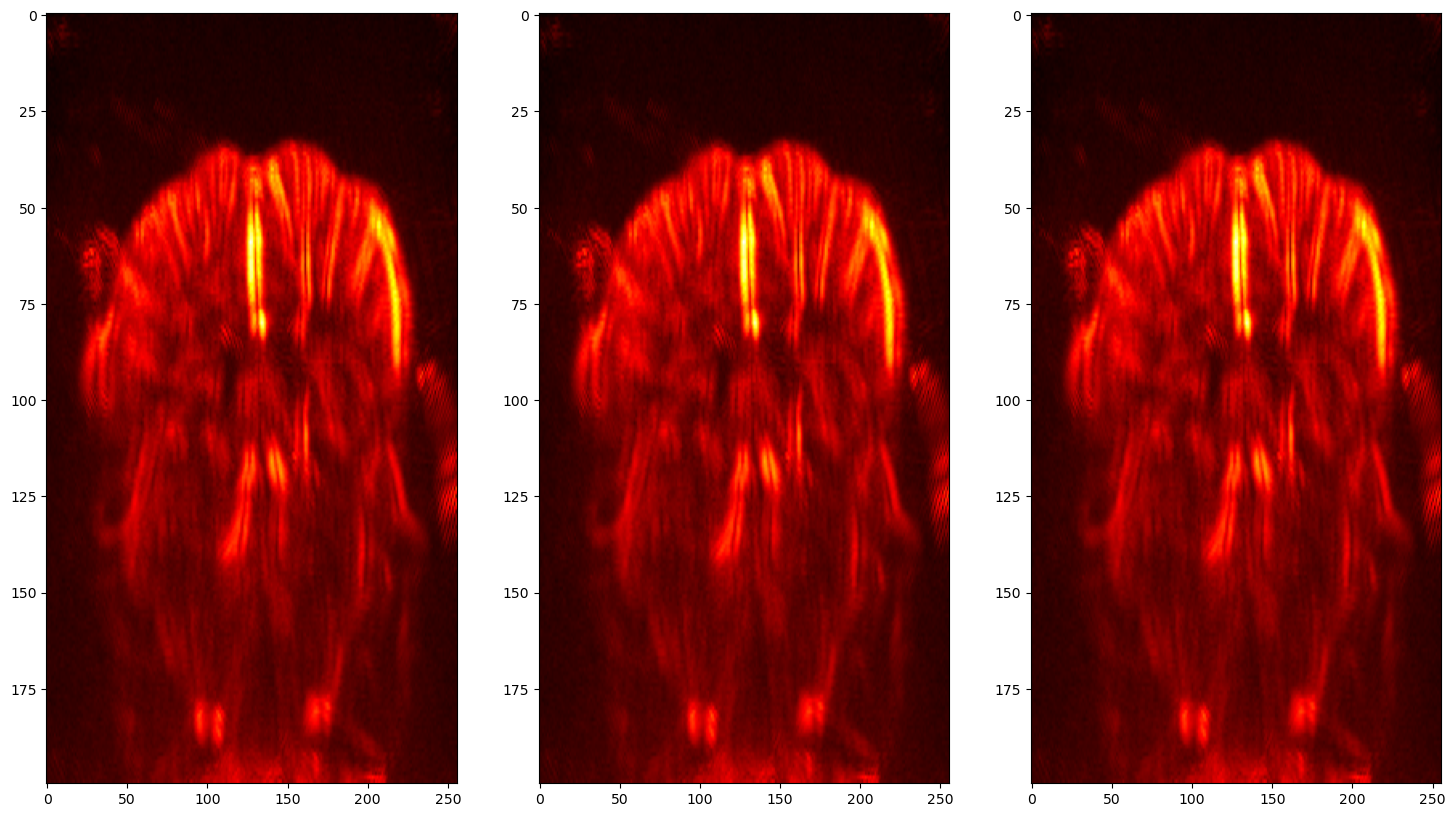

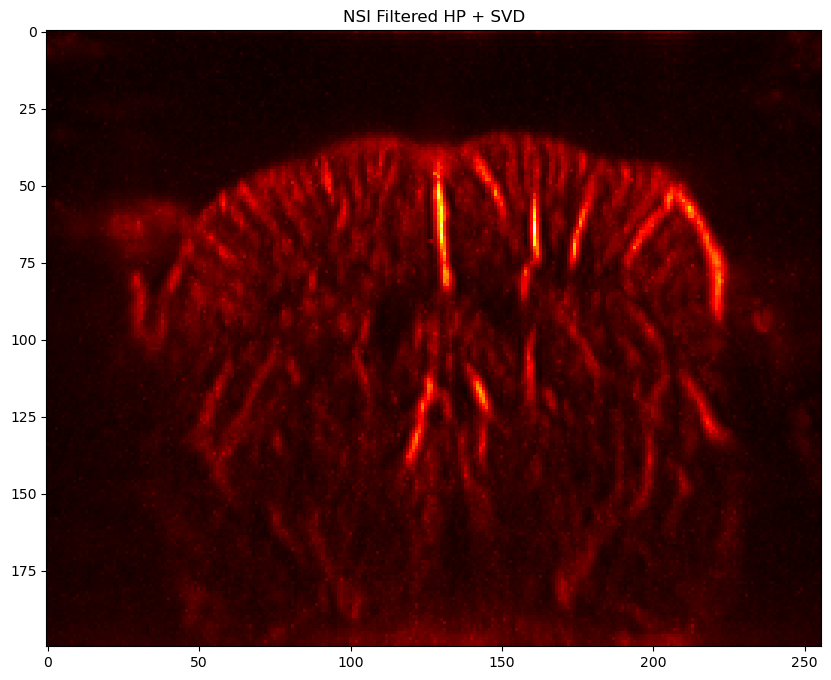

In [80]:
#memmap_env_nsi[:,:,i] = (memmap_bf_matrix_dc1[:,:,i] + memmap_bf_matrix_dc2[:,:,i]) / 2 - memmap_bf_matrix_zm[:,:,i]

if use_nsi and not directional_filter:
    z_limit = filtered_hp_svd.shape[0] // 3

    bff_zm = filtered_hp_svd[:z_limit,:,:]
    bff_dc1 = filtered_hp_svd[z_limit:z_limit*2,:,:]
    bff_dc2 = filtered_hp_svd[z_limit*2:,:,:]

    fig, ax = plt.subplots(ncols = 3, nrows = 1, figsize=(18,10))
    im1 = ax[0].imshow(np.sqrt(np.sum(np.abs(bff_zm), axis=2)), aspect='auto', cmap='hot')
    im2 = ax[1].imshow(np.sqrt(np.sum(np.abs(bff_dc1), axis=2)), aspect='auto', cmap='hot')
    im3 = ax[2].imshow(np.sqrt(np.sum(np.abs(bff_dc2), axis=2)), aspect='auto', cmap='hot')
        
    bff_zm_env = get_envelope(bff_zm, bff_zm.shape[2], complex_bf)
    bff_dc1_env = get_envelope(bff_dc1, bff_dc1.shape[2], complex_bf)
    bff_dc2_env = get_envelope(bff_dc2, bff_dc2.shape[2], complex_bf)
    
    print(f"bff_zm shape: {bff_zm.shape}")
    print(f"bff_dc1 shape: {bff_dc1.shape}")
    print(f"bff_dc2 shape: {bff_dc2.shape}")

    bff_nsi = (bff_dc1_env + bff_dc2_env) / 2 - bff_zm_env
    plt.figure(figsize=(10, 8))
    # plt.imshow(20 * np.log10(np.sum(np.abs(bff_nsi),axis=2) / np.max(np.sum(np.abs(bff_nsi), axis=2))), aspect='auto', cmap='viridis', vmin=-60, vmax=0)
    plt.imshow(np.sqrt(np.sum(np.abs(bff_nsi), axis=2)), aspect='auto', cmap='hot')

    plt.title(f"NSI Filtered HP + SVD")

    if save_data:
        save_beamformed_data(np.sum(np.abs(bff_nsi), axis=2), f"{beamformed_filtered_matrix_name}_nsi", f"{bf_data_path}{folder_name}/filtered_bf/")
    if save_image:
        plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_nsi.png")

    filtered_hp_svd = bff_nsi

elif use_nsi and complex_bf and directional_filter:


    z_limit = filtered_hp_svd.shape[0] // 3

    bff_zm = filtered_hp_svd[:z_limit,:,:]
    bff_dc1 = filtered_hp_svd[z_limit:z_limit*2,:,:]
    bff_dc2 = filtered_hp_svd[z_limit*2:,:,:]
    

    #movement filtered apodizations

    bff_zm_up, bff_dc1_up, bff_dc2_up, min_phase, max_phase = filter_movement_nsi(bff_zm, bff_dc1, bff_dc2, bff_zm.shape[2], "up")

    print(f"Min phase: {min_phase}")
    print(f"Max phase: {max_phase}")

    bff_zm_down, bff_dc1_down, bff_dc2_down, min_phase, max_phase = filter_movement_nsi(bff_zm, bff_dc1, bff_dc2, bff_zm.shape[2], "down")
    
    print(f"Min phase: {min_phase}")
    print(f"Max phase: {max_phase}")

    bff_zm_env_fft_up, bff_zm_env_fft_down = get_doppler_flow_images(bff_zm, sampling_rate)
    bff_dc1_env_fft_up, bff_dc1_env_fft_down = get_doppler_flow_images(bff_dc1, sampling_rate)
    bff_dc2_env_fft_up, bff_dc2_env_fft_down = get_doppler_flow_images(bff_dc2, sampling_rate)

    # bff_zm_up = filter_movement(bff_zm, bff_zm.shape[2], "up")
    # bff_zm_down = filter_movement(bff_zm, bff_zm.shape[2], "down")
# 
    # bff_dc1_up = filter_movement(bff_dc1, bff_dc1.shape[2], "up")
    # bff_dc1_down = filter_movement(bff_dc1, bff_dc1.shape[2], "down")
# 
    # bff_dc2_up = filter_movement(bff_dc2, bff_dc2.shape[2], "up")
    # bff_dc2_down = filter_movement(bff_dc2, bff_dc2.shape[2], "down")

    fig, ax = plt.subplots(ncols = 3, nrows = 1, figsize=(18,6))
    im1 = ax[0].imshow(np.sqrt(np.sum(np.abs(bff_zm_down), axis=2)), aspect='auto', cmap='hot')
    im2 = ax[1].imshow(np.sqrt(np.sum(np.abs(bff_dc1_down), axis=2)), aspect='auto', cmap='hot')
    im3 = ax[2].imshow(np.sqrt(np.sum(np.abs(bff_dc2_down), axis=2)), aspect='auto', cmap='hot')

    fig, ax = plt.subplots(ncols = 3, nrows = 1, figsize=(18,6))
    im1 = ax[0].imshow(np.sqrt(np.sum(np.abs(bff_zm_up), axis=2)), aspect='auto', cmap='hot')
    im2 = ax[1].imshow(np.sqrt(np.sum(np.abs(bff_dc1_up), axis=2)), aspect='auto', cmap='hot')
    im3 = ax[2].imshow(np.sqrt(np.sum(np.abs(bff_dc2_up), axis=2)), aspect='auto', cmap='hot')
    
    #envelopes
    bff_zm_env_up = get_envelope(bff_zm_up, bff_zm.shape[2], complex_bf)
    bff_dc1_env_up = get_envelope(bff_dc1_up, bff_dc1.shape[2], complex_bf)
    bff_dc2_env_up = get_envelope(bff_dc2_up, bff_dc2.shape[2], complex_bf)

    bff_zm_env_down = get_envelope(bff_zm_down, bff_zm.shape[2], complex_bf)
    bff_dc1_env_down = get_envelope(bff_dc1_down, bff_dc1.shape[2], complex_bf)
    bff_dc2_env_down = get_envelope(bff_dc2_down, bff_dc2.shape[2], complex_bf)
    
    print(f"bff_zm shape: {bff_zm.shape}")
    print(f"bff_dc1 shape: {bff_dc1.shape}")
    print(f"bff_dc2 shape: {bff_dc2.shape}")

    bff_zm_env = get_envelope(bff_zm, bff_zm.shape[2], complex_bf)
    bff_dc1_env = get_envelope(bff_dc1, bff_dc1.shape[2], complex_bf)
    bff_dc2_env = get_envelope(bff_dc2, bff_dc2.shape[2], complex_bf)

    # bff_zm_env_fft_up, bff_zm_env_fft_down = get_doppler_flow_images(bff_zm_env, sampling_rate)
    # bff_dc1_env_fft_up, bff_dc1_env_fft_down = get_doppler_flow_images(bff_dc1_env, sampling_rate)
    # bff_dc2_env_fft_up, bff_dc2_env_fft_down = get_doppler_flow_images(bff_dc2_env, sampling_rate)

    fig, ax = plt.subplots(ncols = 3, nrows = 1, figsize=(18,6))
    im1 = ax[0].imshow(np.sqrt(np.abs(bff_zm_env_fft_up)), aspect='auto', cmap='hot')
    im2 = ax[1].imshow(np.sqrt(np.abs(bff_dc1_env_fft_up)), aspect='auto', cmap='hot')
    im3 = ax[2].imshow(np.sqrt(np.abs(bff_dc2_env_fft_up)), aspect='auto', cmap='hot')


    fig, ax = plt.subplots(ncols = 3, nrows = 1, figsize=(18,6))
    im1 = ax[0].imshow(np.sqrt(np.abs(bff_zm_env_fft_down)), aspect='auto', cmap='hot')
    im2 = ax[1].imshow(np.sqrt(np.abs(bff_dc1_env_fft_down)), aspect='auto', cmap='hot')
    im3 = ax[2].imshow(np.sqrt(np.abs(bff_dc2_env_fft_down)), aspect='auto', cmap='hot')


    bff_nsi_fft_up = (bff_dc1_env_fft_up + bff_dc2_env_fft_up) / 2 - bff_zm_env_fft_up 
    bff_nsi_fft_down = (bff_dc1_env_fft_down + bff_dc2_env_fft_down) / 2 - bff_zm_env_fft_down

    bff_nsi_up = (bff_dc1_env_up + bff_dc2_env_up) / 2 - bff_zm_env_up
    bff_nsi_down = (bff_dc1_env_down + bff_dc2_env_down) / 2 - bff_zm_env_down
    bff_nsi = (bff_dc1_env + bff_dc2_env) / 2 - bff_zm_env


    fig, ax = plt.subplots(ncols = 6, nrows = 1, figsize=(18,6))
    # plt.imshow(20 * np.log10(np.sum(np.abs(bff_nsi),axis=2) / np.max(np.sum(np.abs(bff_nsi), axis=2))), aspect='auto', cmap='viridis', vmin=-60, vmax=0)
    im1 = ax[0].imshow(np.sqrt(np.sum(np.abs(bff_nsi_up), axis=2)), aspect='auto', cmap='hot')
    im2 = ax[1].imshow(np.sqrt(np.sum(np.abs(bff_nsi_down), axis=2)), aspect='auto', cmap='hot')
    im3 = ax[2].imshow(np.sqrt(np.sum(np.abs(bff_nsi), axis=2)), aspect='auto', cmap='hot')
    im4 = ax[3].imshow(np.sqrt(np.sum(np.abs(bff_nsi_up + bff_nsi_down), axis=2)), aspect='auto', cmap='hot')
    im5 = ax[4].imshow(np.sqrt(np.abs(bff_nsi_fft_up)), aspect='auto', cmap='hot')
    im6 = ax[5].imshow(np.sqrt(np.abs(bff_nsi_fft_down)), aspect='auto', cmap='hot')


    ax[0].set_title("Up")
    ax[1].set_title("Down")
    ax[2].set_title("NSI")
    ax[3].set_title("NSI Up + Down")
    ax[4].set_title("NSI FFT Up")
    ax[5].set_title("NSI FFT Down")

    plt.title(f"NSI Filtered HP + SVD")

    # if save_data:
    #     save_beamformed_data(np.sum(np.abs(bff_nsi), axis=2), f"{beamformed_filtered_matrix_name}_nsi", f"{bf_data_path}{folder_name}/filtered_bf/")
    # if save_image:
    #     plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_nsi.png")
    filtered_hp_svd = bff_nsi


In [81]:
plt.figure(figsize=(10, 8))
plt.imshow(np.sqrt(np.sum(np.abs(bff_nsi_up), axis=2)), aspect='auto', cmap='hot')
plt.title("Up")
plt.figure(figsize=(10, 8))
plt.imshow(np.sqrt(np.sum(np.abs(bff_nsi_down), axis=2)), aspect='auto', cmap='hot')
plt.title("Down")
plt.figure(figsize=(10, 8))
plt.imshow(np.sqrt(np.sum(np.abs(bff_nsi), axis=2)), aspect='auto', cmap='hot')
plt.title("NSI")
plt.figure(figsize=(10, 8))
plt.imshow(np.sqrt(np.sum(np.abs(bff_nsi_up + bff_nsi_down), axis=2)), aspect='auto', cmap='hot')
plt.title("NSI Up + Down")
if save_image:
    plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_phase_nsi.png")
plt.figure(figsize=(10, 8))
plt.imshow(np.sqrt(np.abs(bff_nsi_fft_up)), aspect='auto', cmap='hot')
plt.title("NSI FFT Up")
plt.figure(figsize=(10, 8))
plt.imshow(np.sqrt(np.abs(bff_nsi_fft_down)), aspect='auto', cmap='hot')
plt.title("NSI FFT Down")
plt.figure(figsize=(10, 8))
plt.imshow(np.sqrt(np.abs(bff_nsi_fft_up + bff_nsi_fft_down)), aspect='auto', cmap='hot')
plt.title("NSI Up + Down")
if save_image:
    plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_fft_nsi.png")


NameError: name 'bff_nsi_up' is not defined

<Figure size 1000x800 with 0 Axes>

In [ ]:
phase1 = np.angle(bff_zm)
phase2 = np.angle(bff_dc1)
phase3 = np.angle(bff_dc2)

phases = [phase1, phase2, phase3]

In [ ]:
phases[2].shape

(200, 256, 640)

# Benchmark results

In [ ]:
matrix_to_analyze = 20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2)))

Signal: -27.39 dB, Noise: -45.11 dB, SNR: 17.72 dB


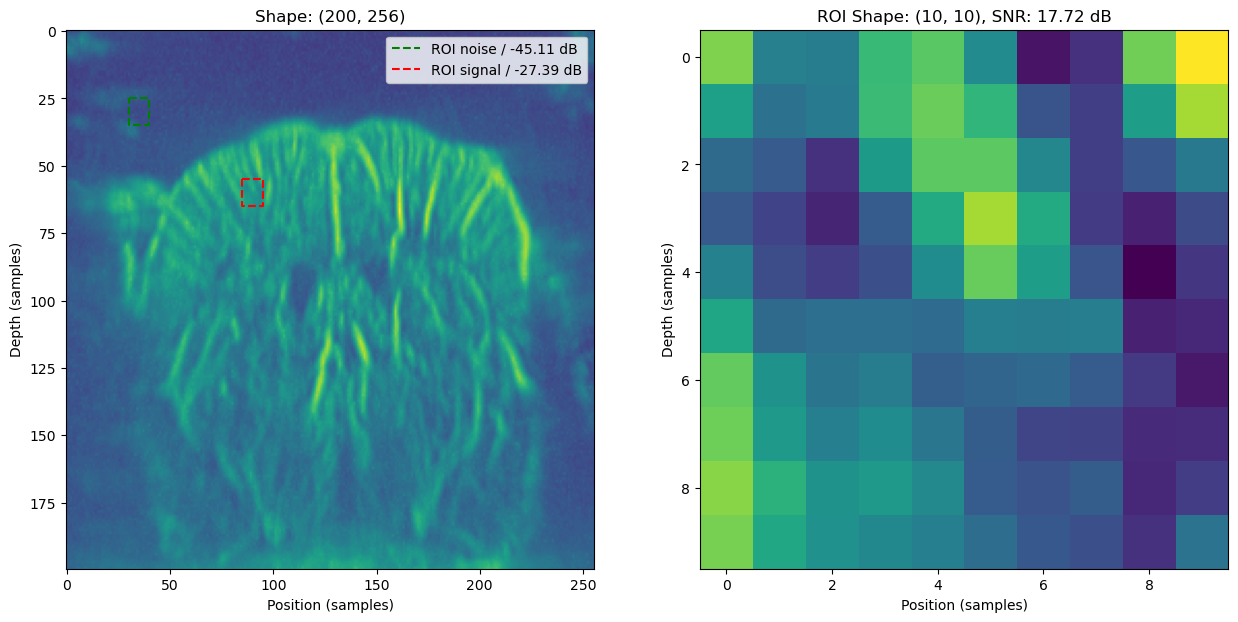

In [ ]:
x0_noise = 30
z0_noise = 25
nx_noise = 10
nz_noise = 10


x0_roi = 85
z0_roi = 55
nx_roi = 10
nz_roi = 10

sub_plot_size = 1 if nx_roi == None or nz_roi == None else 2

fig, ax = plt.subplots(1, sub_plot_size, figsize=(15, 7))

if sub_plot_size == 1:
    ax = [ax]

#define noise region of interest
noise_matrix = matrix_to_analyze[z0_noise:z0_noise+nz_noise, x0_noise:x0_noise+nx_noise]
Pnoise = np.mean(noise_matrix)
ax[0].plot([x0_noise, x0_noise+nx_noise, x0_noise+nx_noise, x0_noise, x0_noise], [z0_noise, z0_noise, z0_noise+nz_noise, z0_noise+nz_noise, z0_noise], 'g--', label=f'ROI noise / {Pnoise:.2f} dB')


ax[0].imshow(matrix_to_analyze, aspect='auto', cmap='viridis', vmin=-60, vmax=0)
ax[0].set_xlabel("Position (samples)")
ax[0].set_ylabel("Depth (samples)")
ax[0].set_title(f"Shape: {matrix_to_analyze.shape}")

data = matrix_to_analyze[z0_roi:z0_roi+nz_roi, x0_roi:x0_roi+nx_roi]
Psignal= np.mean(data)

ax[0].plot([x0_roi, x0_roi+nx_roi, x0_roi+nx_roi, x0_roi, x0_roi], [z0_roi, z0_roi, z0_roi+nz_roi, z0_roi+nz_roi, z0_roi], 'r--', label=f'ROI signal / {Psignal:.2f} dB')
ax[0].legend()

ax[1].imshow(data, aspect='auto', cmap='viridis')
ax[1].set_xlabel("Position (samples)")
ax[1].set_ylabel("Depth (samples)")

snr_db = Psignal - Pnoise

ax[1].set_title(f"ROI Shape: {data.shape}, SNR: {snr_db:.2f} dB")

print(f"Signal: {Psignal:.2f} dB, Noise: {Pnoise:.2f} dB, SNR: {snr_db:.2f} dB")

plt.show()

In [ ]:
def visualize_directional_flow(rf_data, frames):

    amplitude = np.abs(rf_data)
    instantaneous_phase = np.angle(rf_data)

    phase_shifts = np.zeros_like(rf_data)

    
    for i in range(0, rf_data.shape[1]):    #tranducers
        for j in range(0, rf_data.shape[0]):    #samples depth
            for k in range(1 , frames):  #frames

                phase_shifts[j,i,k] = instantaneous_phase[j,i,k] - instantaneous_phase[j,i,k-1]
    
    #sum all amplitudes for frame - later for intensity
    cumulative_amplitude = np.sum(amplitude, axis=2)
    cumulative_amplitude = cumulative_amplitude / np.max(cumulative_amplitude)  #norm between 0 and 1
    
    #flow image with last axis being rgb channels 
    flow_image = np.zeros((rf_data.shape[0], rf_data.shape[1], 3))
    
    #flow image making with red and blue channels
    for i in range(0, rf_data.shape[1]):    # transducers
        for j in range(0, rf_data.shape[0]):    # samples depth
            upward_sum = 0
            downward_sum = 0
            
            for k in range(1, frames):  # frames
                phase_shift = phase_shifts[j,i,k]
                signal_amplitude = amplitude[j,i,k]
                
                if phase_shift > 0:  # up movement
                    upward_sum += signal_amplitude
                else:  # down movement
                    downward_sum += signal_amplitude
            

            total = upward_sum + downward_sum
            if total > 0:
                upward_ratio = upward_sum / total #norme once more between 0 and 1
                downward_ratio = downward_sum / total
                
                intensity = cumulative_amplitude[j,i]
                flow_image[j,i,2] = downward_ratio * intensity  #blue
                flow_image[j,i,0] = upward_ratio * intensity    #red
    
    return flow_image

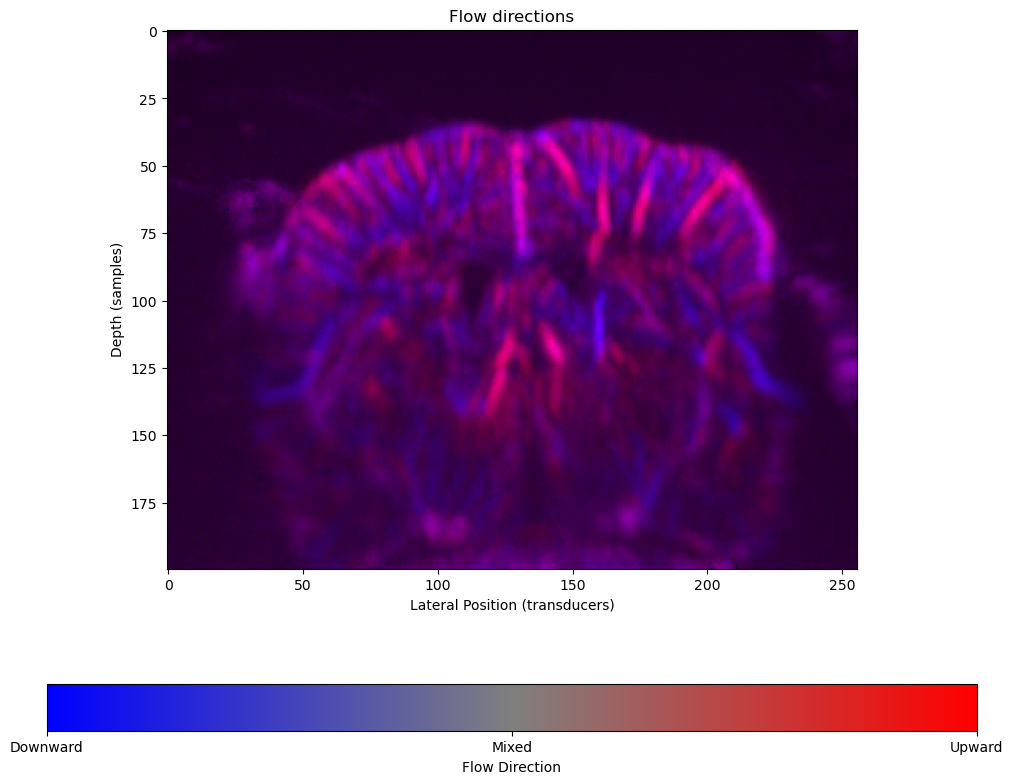

In [ ]:
if complex_bf and not use_nsi:
    flow_image = visualize_directional_flow(filtered_hp_svd, filtered_hp_svd.shape[2])
        
    plt.figure(figsize=(12, 10))

    plt.imshow(np.sqrt(flow_image))
    plt.title("Flow directions")
    plt.xlabel("Lateral Position (transducers)")
    plt.ylabel("Depth (samples)")


    cmap_colors = [(0, 0, 1), (0.5, 0.5, 0.5), (1, 0, 0)]  #RGB color map (in RGB format)
    custom_cmap = LinearSegmentedColormap.from_list('custom', cmap_colors)

    cb = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap),ax=plt.gca(), orientation='horizontal')
    cb.set_ticks([0, 0.5, 1])
    cb.set_ticklabels(['Downward', 'Mixed', 'Upward'])
    cb.set_label('Flow Direction')
elif use_nsi and directional_filter:

    flow_image = np.zeros((filtered_hp_svd.shape[0], filtered_hp_svd.shape[1], 3))
    flow_image[:, :, 0] = np.sqrt(np.abs(bff_nsi_fft_up)) / np.max(np.sqrt(np.abs(bff_nsi_fft_up)))
    flow_image[:, :, 2] = np.sqrt(np.abs(bff_nsi_fft_down)) / np.max(np.sqrt(np.abs(bff_nsi_fft_down)))
    plt.figure(figsize=(12, 10))

    plt.imshow(np.sqrt(flow_image))
    plt.title("Flow directions")
    plt.xlabel("Lateral Position (transducers)")
    plt.ylabel("Depth (samples)")

    cmap_colors = [(0, 0, 1), (0.5, 0.5, 0.5), (1, 0, 0)]  #RGB color map (in RGB format)
    custom_cmap = LinearSegmentedColormap.from_list('custom', cmap_colors)

    cb = plt.colorbar(plt.cm.ScalarMappable(cmap=custom_cmap),ax=plt.gca(), orientation='horizontal')
    cb.set_ticks([0, 0.5, 1])
    cb.set_ticklabels(['Downward', 'Mixed', 'Upward'])
    cb.set_label('Flow Direction')



In [ ]:
# up = np.load('/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_filtered/mouse_test_pre/filtered_bf/002_bff_IQ_up_nsi.npy')
# down = np.load('/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_filtered/mouse_test_pre/filtered_bf/002_bff_IQ_down_nsi.npy')

In [ ]:
# plt.figure(figsize=(12, 10))
# plt.imshow(np.sqrt(up))
# plt.figure(figsize=(12, 10))
# plt.imshow(np.sqrt(down))
# plt.figure(figsize=(12, 10))    
# plt.imshow(np.sqrt(up + down))